# Statistical Inference and Temporal Trends

## 1. Confidence Intervals for Biodiversity Indicators

Annual estimates give equal weight to each contributing route. We use
95% Student's t-confidence intervals based on variation among route-level
values, excluding missing values separately for each indicator.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
route_year = pd.read_csv(ROOT / "data/processed/route_year_indicators.csv")

indicators = ["richness", "recorded_abundance", "shannon"]
labels = {
    "richness": "Species richness",
    "recorded_abundance": "Recorded abundance",
    "shannon": "Shannon diversity",
}

print(route_year.shape)
display(route_year.head())
print(route_year.columns.tolist())

(723, 5)


,route_key,year,richness,recorded_abundance,shannon
0,anse couleuvre,2014,4.500000,8.55,1.370119
1,anse couleuvre,2015,6.000000,9.65,1.577190
2,anse couleuvre,2016,5.500000,8.95,1.572054
3,anse couleuvre,2017,4.294118,7.10,1.299908
4,anse couleuvre,2018,3.941176,6.85,1.179100


['route_key', 'year', 'richness', 'recorded_abundance', 'shannon']


In [2]:
def t_confidence_interval(estimate, standard_error, df, confidence=0.95):
    """Two-sided Student's t interval with the supplied degrees of freedom."""
    critical_value = stats.t.ppf(1 - (1 - confidence) / 2, df=df)
    margin = critical_value * standard_error
    return estimate - margin, estimate + margin


def mean_confidence_interval(values, confidence=0.95):
    """Mean and t interval after omitting missing values; n < 2 has no interval."""
    values = pd.Series(values).dropna()
    n = len(values)
    mean = values.mean()
    se = values.std(ddof=1) / np.sqrt(n) if n >= 2 else np.nan
    lower, upper = (
        t_confidence_interval(mean, se, df=n - 1, confidence=confidence)
        if n >= 2 else (np.nan, np.nan)
    )
    return pd.Series({
        "mean": mean,
        "n": n,
        "se": se,
        "ci_lower": lower,
        "ci_upper": upper,
    })


def annual_confidence_intervals(data, value_column):
    """Summarize one value per route-year, giving each route equal weight."""
    return (
        data.groupby("year", sort=True)[value_column]
        .apply(mean_confidence_interval)
        .unstack()
        .reset_index()
    )

### Route-Level Species Richness in 2014

In [3]:
richness_2014 = route_year.loc[route_year["year"].eq(2014), "richness"].dropna()
richness_summary = mean_confidence_interval(richness_2014)

print(f"Number of routes: {len(richness_2014)}")
print(f"Mean species richness: {richness_summary['mean']:.4f}")
print(f"Sample standard deviation: {richness_2014.std(ddof=1):.4f}")
print(f"Standard error: {richness_summary['se']:.4f}")
print(
    f"95% confidence interval: "
    f"[{richness_summary['ci_lower']:.4f}, {richness_summary['ci_upper']:.4f}]"
)

Number of routes: 40
Mean species richness: 6.4322
Sample standard deviation: 1.7848
Standard error: 0.2822
95% confidence interval: [5.8614, 7.0030]


### Annual Estimates, 2014–2025

In [4]:
ci_tables = {
    indicator: annual_confidence_intervals(route_year, indicator)
    for indicator in indicators
}

for indicator, table in ci_tables.items():
    print(f"\n{indicator.upper()}")
    display(table.round(4))


RICHNESS


,year,mean,n,se,ci_lower,ci_upper
0,2014,6.4322,40.0,0.2822,5.8614,7.0030
1,2015,7.3533,53.0,0.2085,6.9350,7.7716
2,2016,7.7539,59.0,0.1994,7.3549,8.1530
3,2017,7.7253,60.0,0.2405,7.2441,8.2066
4,2018,7.4403,64.0,0.2113,7.0180,7.8626
5,2019,7.5680,64.0,0.2150,7.1384,7.9976
6,2020,8.3918,63.0,0.2188,7.9543,8.8292
7,2021,8.3256,63.0,0.2582,7.8095,8.8417
8,2022,8.3034,63.0,0.2736,7.7565,8.8503
9,2023,7.9920,64.0,0.2438,7.5048,8.4793



RECORDED_ABUNDANCE


,year,mean,n,se,ci_lower,ci_upper
0,2014,14.0114,40.0,0.9017,12.1876,15.8351
1,2015,16.2893,53.0,0.8967,14.4899,18.0887
2,2016,16.5122,59.0,0.7485,15.0139,18.0105
3,2017,17.5533,60.0,1.1306,15.2910,19.8157
4,2018,15.8406,64.0,0.8590,14.1241,17.5572
5,2019,16.9029,64.0,0.8772,15.1499,18.6559
6,2020,18.7225,63.0,0.9383,16.8470,20.5980
7,2021,19.0750,63.0,0.9939,17.0883,21.0617
8,2022,19.2121,63.0,1.0407,17.1316,21.2925
9,2023,17.8477,64.0,0.9555,15.9383,19.7571



SHANNON


,year,mean,n,se,ci_lower,ci_upper
0,2014,1.6665,39.0,0.0313,1.6031,1.7299
1,2015,1.7677,53.0,0.0245,1.7185,1.8170
2,2016,1.8299,59.0,0.0251,1.7795,1.8802
3,2017,1.8136,60.0,0.0298,1.7540,1.8733
4,2018,1.7679,64.0,0.0295,1.7089,1.8269
5,2019,1.7796,64.0,0.0292,1.7212,1.8380
6,2020,1.8948,63.0,0.0277,1.8394,1.9503
7,2021,1.8738,63.0,0.0326,1.8086,1.9390
8,2022,1.8760,63.0,0.0333,1.8094,1.9427
9,2023,1.8415,64.0,0.0315,1.7785,1.9045


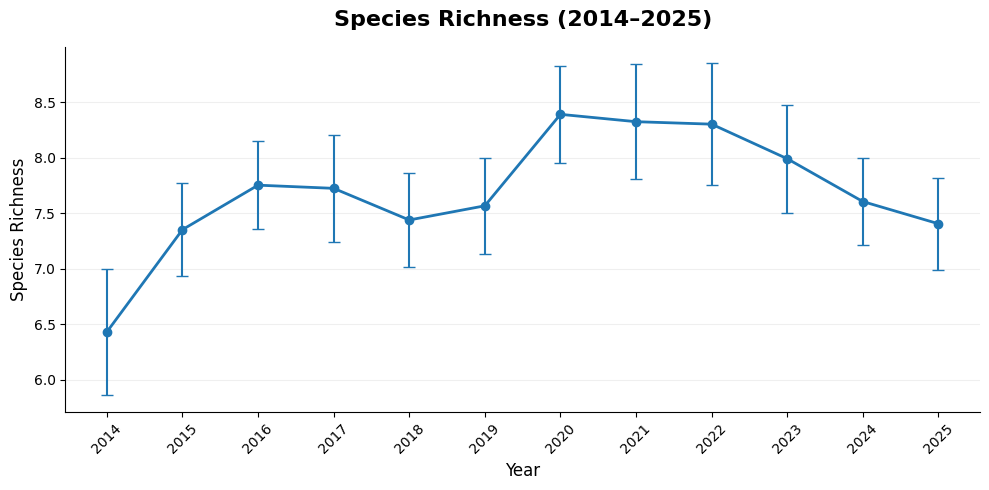

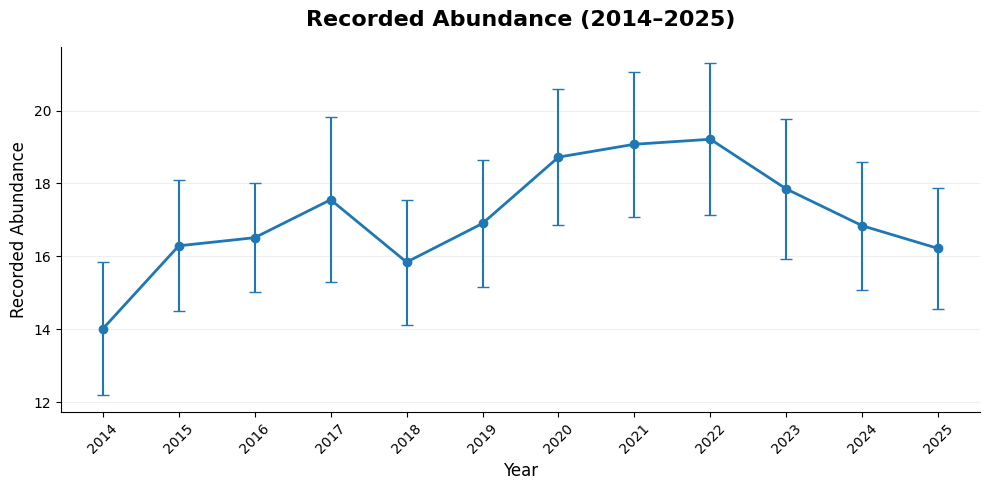

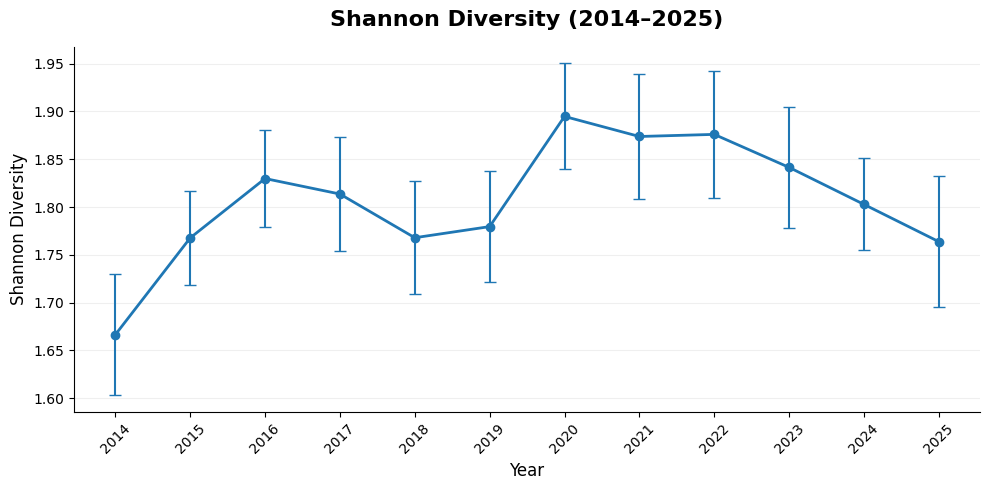

In [5]:
for indicator, table in ci_tables.items():

    lower_error = table["mean"] - table["ci_lower"]
    upper_error = table["ci_upper"] - table["mean"]

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.errorbar(
        table["year"],
        table["mean"],
        yerr=[lower_error, upper_error],
        fmt="o-",
        capsize=4,
        markersize=6,
        linewidth=2,
        elinewidth=1.5
    )

    ax.set_title(
        f"{labels[indicator].title()} (2014–2025)",
        fontsize=16,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Year", fontsize=12)
    ax.set_ylabel(labels[indicator].title(), fontsize=12)

    ax.set_xticks(range(2014, 2026))
    ax.tick_params(axis="x", rotation=45)

    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    fig.savefig(
        f"{indicator}_confidence_intervals.png",
        dpi=300,
        bbox_inches="tight",
        transparent=True
    )

    plt.show()

## 2. Temporal Trend Analysis

### Linear Regression

We fit an unweighted linear regression to the 12 annual means:

$$
Y_y = \beta_0 + \beta_1(y - 2014) + \epsilon_y.
$$

The slope $\beta_1$ represents annual change. We test
$H_0: \beta_1 = 0$ against $H_1: \beta_1 \ne 0$, then examine whether
a quadratic model better describes the temporal pattern.

In [6]:
linear_models = {
    indicator: stats.linregress(table["year"] - 2014, table["mean"])
    for indicator, table in ci_tables.items()
}
richness_trend = linear_models["richness"]

print(f"Intercept: {richness_trend.intercept:.4f}")
print(f"Slope: {richness_trend.slope:.4f} species per year")
print(f"R-squared: {richness_trend.rvalue**2:.4f}")
print(f"P-value: {richness_trend.pvalue:.4f}")
print(f"Standard error of slope: {richness_trend.stderr:.4f}")

Intercept: 7.2871
Slope: 0.0735 species per year
R-squared: 0.2395
P-value: 0.1064
Standard error of slope: 0.0414


The fitted mean richness in 2014 is 7.2871 species. The estimated slope
is 0.0735 species per year, and $R^2 = 0.2395$: time explains about 24%
of the variation among annual means.

With $p = 0.1064$, we do not reject a zero slope at the 5% level.
This does not establish the absence of a trend.

### 95% Confidence Interval for the Slope

In [7]:
slope_ci_lower, slope_ci_upper = t_confidence_interval(
    richness_trend.slope,
    richness_trend.stderr,
    df=len(ci_tables["richness"]) - 2,
)
print(f"95% CI for slope: [{slope_ci_lower:.4f}, {slope_ci_upper:.4f}]")

95% CI for slope: [-0.0188, 0.1659]


Simple linear regression has $n - 2 = 10$ residual degrees of freedom:

$$
\hat{\beta}_1 \pm t_{0.975,10}\,SE(\hat{\beta}_1)
\approx 0.0735 \pm 2.228 \times 0.04144
= [-0.0188,\ 0.1659].
$$

In [8]:
trend_results = pd.DataFrame([
    {
        "indicator": indicator,
        "slope": result.slope,
        "intercept": result.intercept,
        "r_squared": result.rvalue**2,
        "p_value": result.pvalue,
        "slope_se": result.stderr,
    }
    for indicator, result in linear_models.items()
])
display(trend_results.round(4))

,indicator,slope,intercept,r_squared,p_value,slope_se
0,richness,0.0735,7.2871,0.2395,0.1064,0.0414
1,recorded_abundance,0.2041,15.9628,0.2404,0.1056,0.1147
2,shannon,0.0077,1.7639,0.1939,0.1520,0.0050


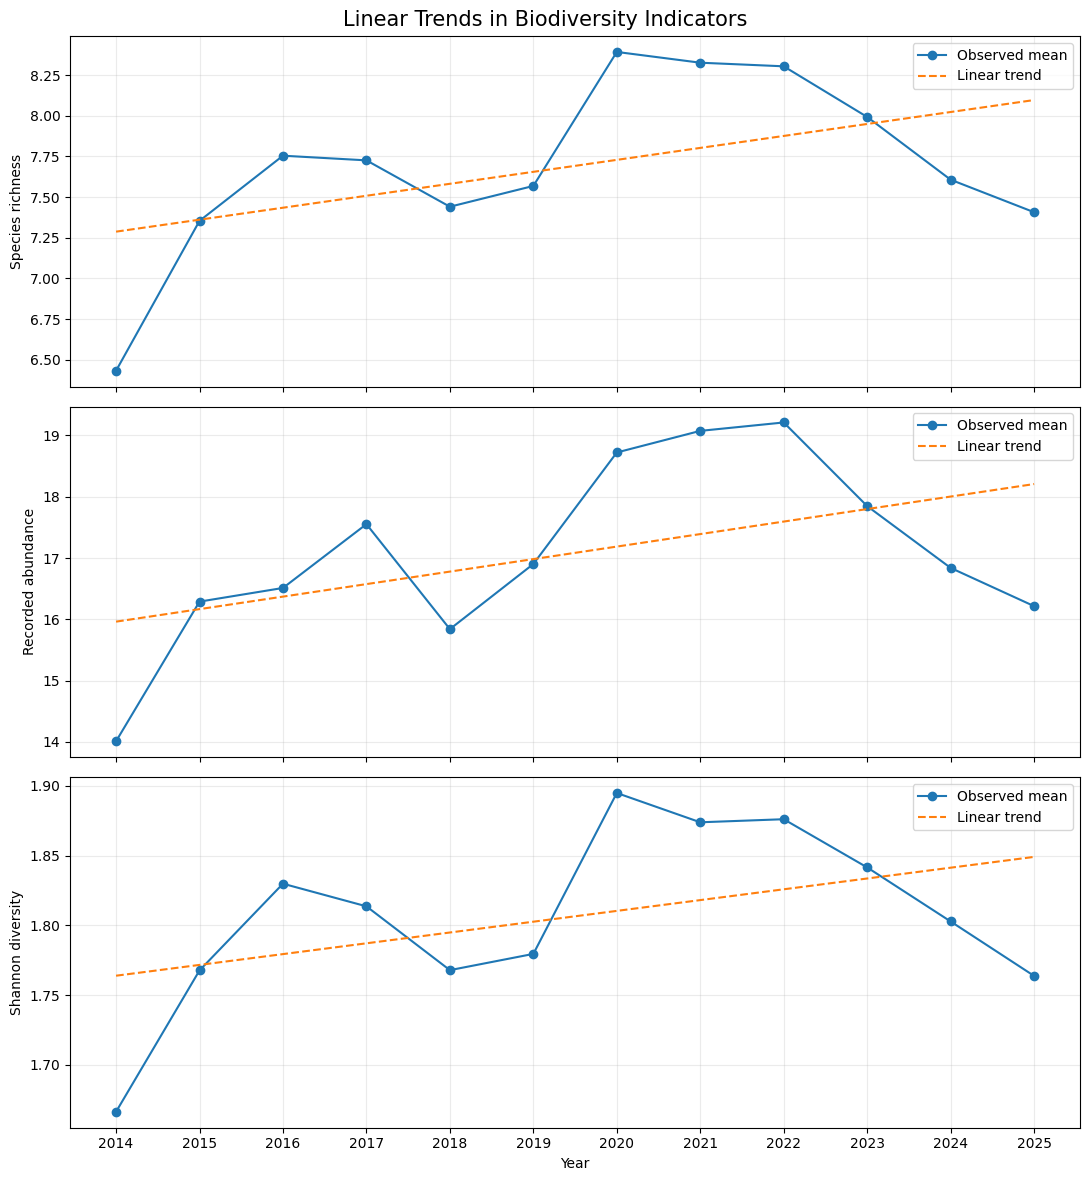

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

for ax, indicator in zip(axes, indicators):
    table = ci_tables[indicator]

    x = table["year"] - 2014
    y = table["mean"]

    result = linear_models[indicator]

    y_fitted = result.intercept + result.slope * x

    ax.plot(table["year"], y, "o-", label="Observed mean")
    ax.plot(table["year"], y_fitted, "--", label="Linear trend")

    ax.set_ylabel(labels[indicator])
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(range(2014, 2026))

fig.suptitle("Linear Trends in Biodiversity Indicators", fontsize=15)

plt.tight_layout()
plt.show()

### 2.1 Quadratic Trend Analysis

Annual estimates peak around 2020–2022. We compare two nested models:

$$
\begin{aligned}
\text{Linear:}\quad &Y(t) = \beta_0 + \beta_1 t + \epsilon,\\
\text{Quadratic:}\quad &Y(t) = \beta_0 + \beta_1 t + \beta_2 t^2 + \epsilon,
\end{aligned}
$$

where $t = \text{year} - 2014$. A nested-model F-test assesses the
additional quadratic term. Turning years are reported only within 2014–2025.

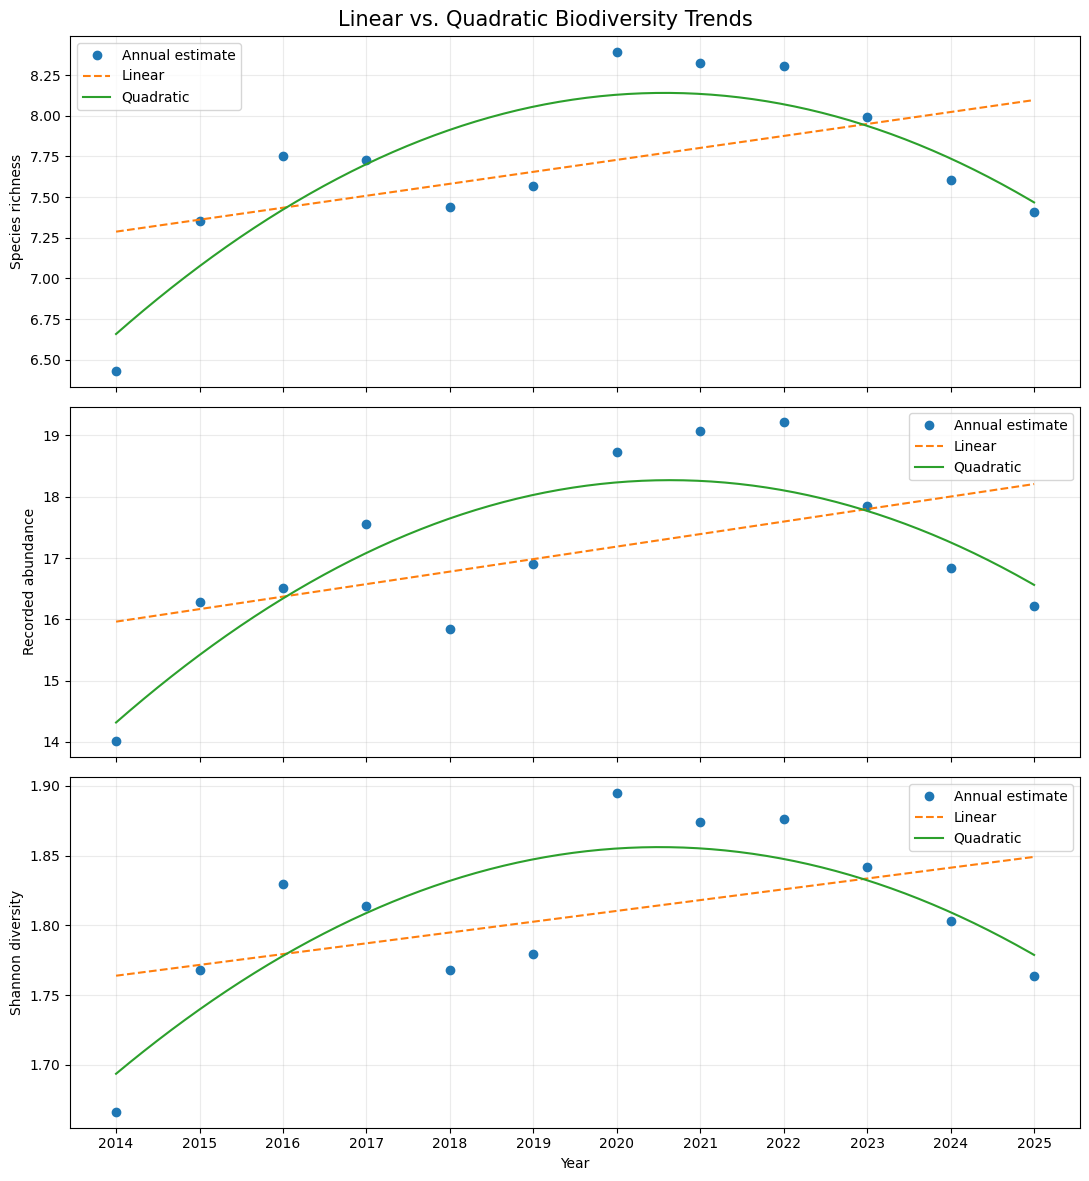

,indicator,beta_2,r2_linear,r2_quadratic,F_statistic,p_value,turning_year
0,richness,-0.0343,0.2395,0.7263,16.0107,0.0031,2020.5714
1,recorded_abundance,-0.0898,0.2404,0.6744,11.9985,0.0071,2020.6367
2,shannon,-0.0038,0.1939,0.6375,11.0157,0.0090,2020.5098


In [10]:
def fit_polynomial_trend(t, y, degree):
    """Fit an unweighted polynomial by least squares, retaining residuals."""
    design = np.column_stack([np.ones(len(t)), *[t**k for k in range(1, degree + 1)]])
    coefficients = np.linalg.lstsq(design, y, rcond=None)[0]
    residuals = y - design @ coefficients
    rss = np.sum(residuals**2)
    return {
        "coefficients": coefficients,
        "residuals": residuals,
        "rss": rss,
        "df": len(y) - design.shape[1],
        "r_squared": 1 - rss / np.sum((y - y.mean())**2),
    }


def nested_f_test(reduced, full):
    """Compare nested least-squares fits to the same observations."""
    df_difference = reduced["df"] - full["df"]
    statistic = ((reduced["rss"] - full["rss"]) / df_difference) / (
        full["rss"] / full["df"]
    )
    return statistic, stats.f.sf(statistic, df_difference, full["df"])


polynomial_models = {}
quadratic_results = []

for indicator, table in ci_tables.items():
    t = (table["year"] - 2014).to_numpy()
    y = table["mean"].to_numpy()
    linear = fit_polynomial_trend(t, y, degree=1)
    quadratic = fit_polynomial_trend(t, y, degree=2)
    polynomial_models[indicator] = {"linear": linear, "quadratic": quadratic}
    f_statistic, p_value = nested_f_test(linear, quadratic)

    beta = quadratic["coefficients"]
    turning_year = np.nan
    if not np.isclose(beta[2], 0):
        candidate = 2014 - beta[1] / (2 * beta[2])
        if 2014 <= candidate <= 2025:
            turning_year = candidate

    quadratic_results.append({
        "indicator": indicator,
        "beta_2": beta[2],
        "r2_linear": linear["r_squared"],
        "r2_quadratic": quadratic["r_squared"],
        "F_statistic": f_statistic,
        "p_value": p_value,
        "turning_year": turning_year,
    })

fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)
for ax, indicator in zip(axes, indicators):
    table = ci_tables[indicator]
    t = (table["year"] - 2014).to_numpy()
    t_fine = np.linspace(t.min(), t.max(), 200)
    beta_linear = polynomial_models[indicator]["linear"]["coefficients"]
    beta_quad = polynomial_models[indicator]["quadratic"]["coefficients"]

    ax.plot(table["year"], table["mean"], "o", label="Annual estimate")
    ax.plot(
        2014 + t_fine, beta_linear[0] + beta_linear[1] * t_fine,
        "--", label="Linear",
    )
    ax.plot(
        2014 + t_fine, beta_quad[0] + beta_quad[1] * t_fine + beta_quad[2] * t_fine**2,
        "-", label="Quadratic",
    )
    ax.set_ylabel(labels[indicator])
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(range(2014, 2026))
fig.suptitle("Linear vs. Quadratic Biodiversity Trends", fontsize=15)
plt.tight_layout()
plt.show()

quadratic_results = pd.DataFrame(quadratic_results)
display(quadratic_results.round(4))

### 2.2 Residual Autocorrelation: Durbin–Watson Statistic

$$
DW = \frac{\sum_{t=2}^{n}(\hat{\epsilon}_t - \hat{\epsilon}_{t-1})^2}
{\sum_{t=1}^{n}\hat{\epsilon}_t^2}.
$$

We examine first-order autocorrelation in the quadratic model residuals,
ordered by year. Values near 2 suggest little autocorrelation; values below
or above 2 suggest positive or negative autocorrelation, respectively.
With only 12 annual observations, this diagnostic requires caution.

In [11]:
def durbin_watson(residuals):
    """First-order residual diagnostic; residuals must be in time order."""
    return np.sum(np.diff(residuals)**2) / np.sum(residuals**2)


dw_statistics = {
    indicator: durbin_watson(models["quadratic"]["residuals"])
    for indicator, models in polynomial_models.items()
}
dw_results = pd.DataFrame([
    {"indicator": indicator, "durbin_watson": value}
    for indicator, value in dw_statistics.items()
])
display(dw_results.round(4))

,indicator,durbin_watson
0,richness,1.4017
1,recorded_abundance,1.4524
2,shannon,1.4590


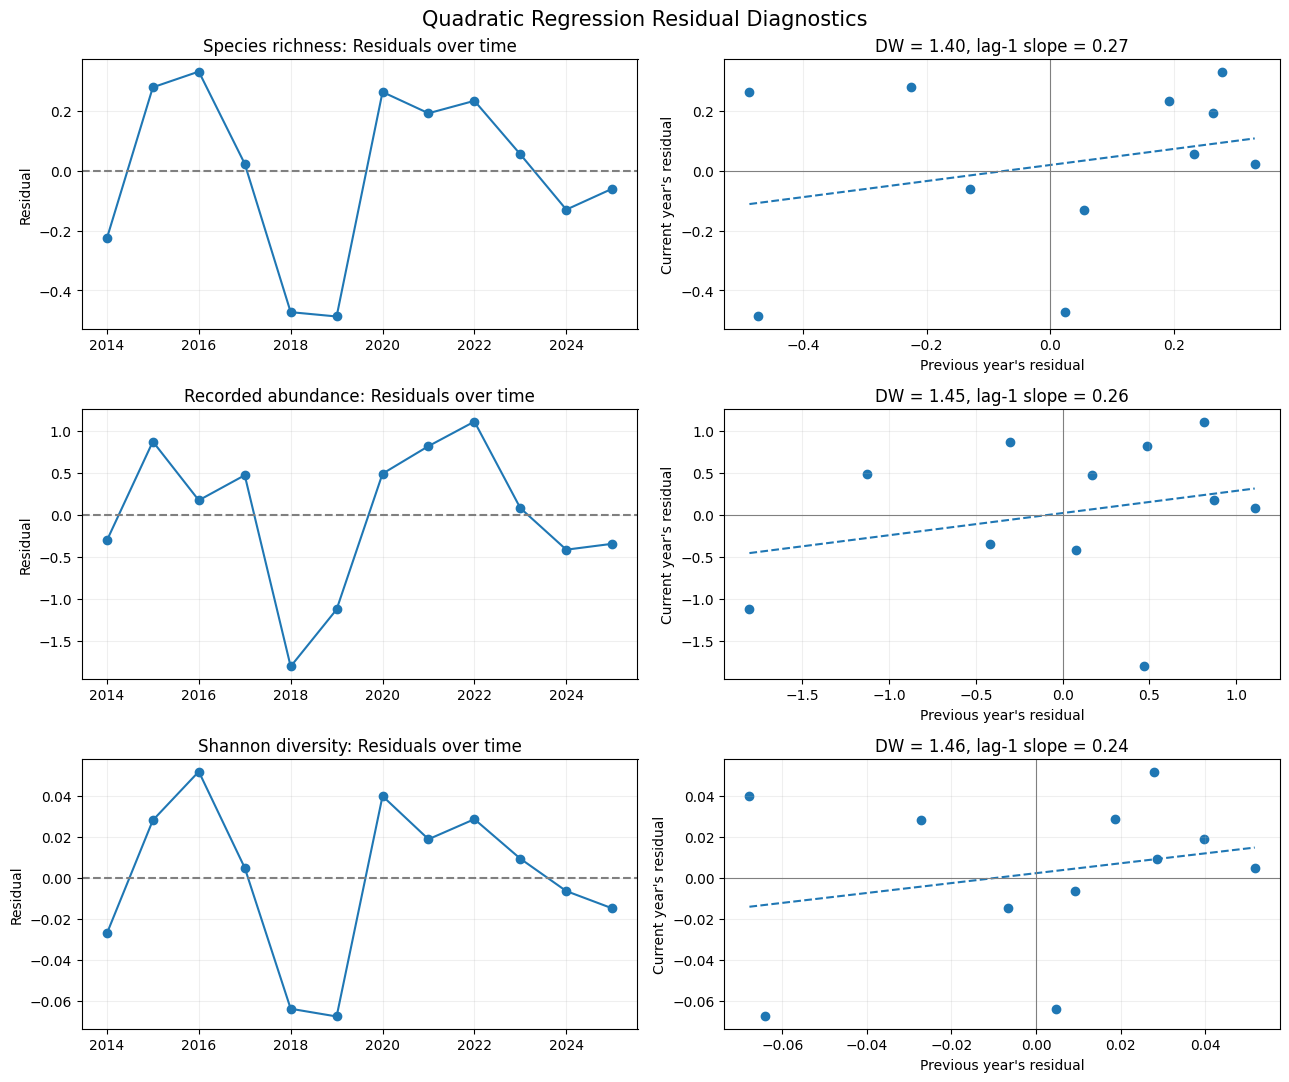

,indicator,dw,lag1_slope,lag1_correlation
0,richness,1.4017,0.2681,0.2763
1,recorded_abundance,1.4524,0.2637,0.2632
2,shannon,1.4590,0.2416,0.2461


In [12]:
fig, axes = plt.subplots(3, 2, figsize=(13, 11))

ar1_results = []

for i, indicator in enumerate(indicators):

    years = ci_tables[indicator]["year"].to_numpy()
    residuals = polynomial_models[indicator]["quadratic"]["residuals"]
    previous, current = residuals[:-1], residuals[1:]
    ar1 = stats.linregress(previous, current)
    dw = dw_statistics[indicator]

    ar1_results.append({
        "indicator": indicator,
        "dw": dw,
        "lag1_slope": ar1.slope,
        "lag1_correlation": ar1.rvalue
    })

    ax = axes[i, 0]

    ax.plot(years, residuals, "o-")
    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(f"{labels[indicator]}: Residuals over time")
    ax.set_ylabel("Residual")
    ax.grid(alpha=0.2)

    ax = axes[i, 1]

    ax.scatter(previous, current)

    x_line = np.linspace(previous.min(), previous.max(), 100)
    y_line = ar1.intercept + ar1.slope * x_line

    ax.plot(x_line, y_line, "--")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)

    ax.set_title(
        f"DW = {dw:.2f}, lag-1 slope = {ar1.slope:.2f}"
    )
    ax.set_xlabel("Previous year's residual")
    ax.set_ylabel("Current year's residual")
    ax.grid(alpha=0.2)

fig.suptitle("Quadratic Regression Residual Diagnostics", fontsize=15)

plt.tight_layout()
plt.show()

ar1_results = pd.DataFrame(ar1_results)

display(ar1_results.round(4))

### Interpretation of Residual Autocorrelation

Durbin–Watson values are 1.4017 for richness, 1.4524 for recorded abundance,
and 1.4590 for Shannon diversity. All suggest possible positive residual
autocorrelation, but do not establish its statistical significance with
only 12 observations. Conventional regression p-values therefore require
caution; the quadratic fits remain exploratory descriptions.

## 3. Sensitivity to Monitoring Route Composition

The set of monitored routes changes between 2014 and 2025.
Consequently, changes in annual biodiversity indicators may partly
reflect changes in geographic coverage rather than changes in
biodiversity within existing routes.

We compare the annual estimates using all available routes with
estimates restricted to routes monitored in both 2014 and 2025.

This is a sensitivity analysis, not a correction for all sampling bias.

Routes in both endpoint years: 41


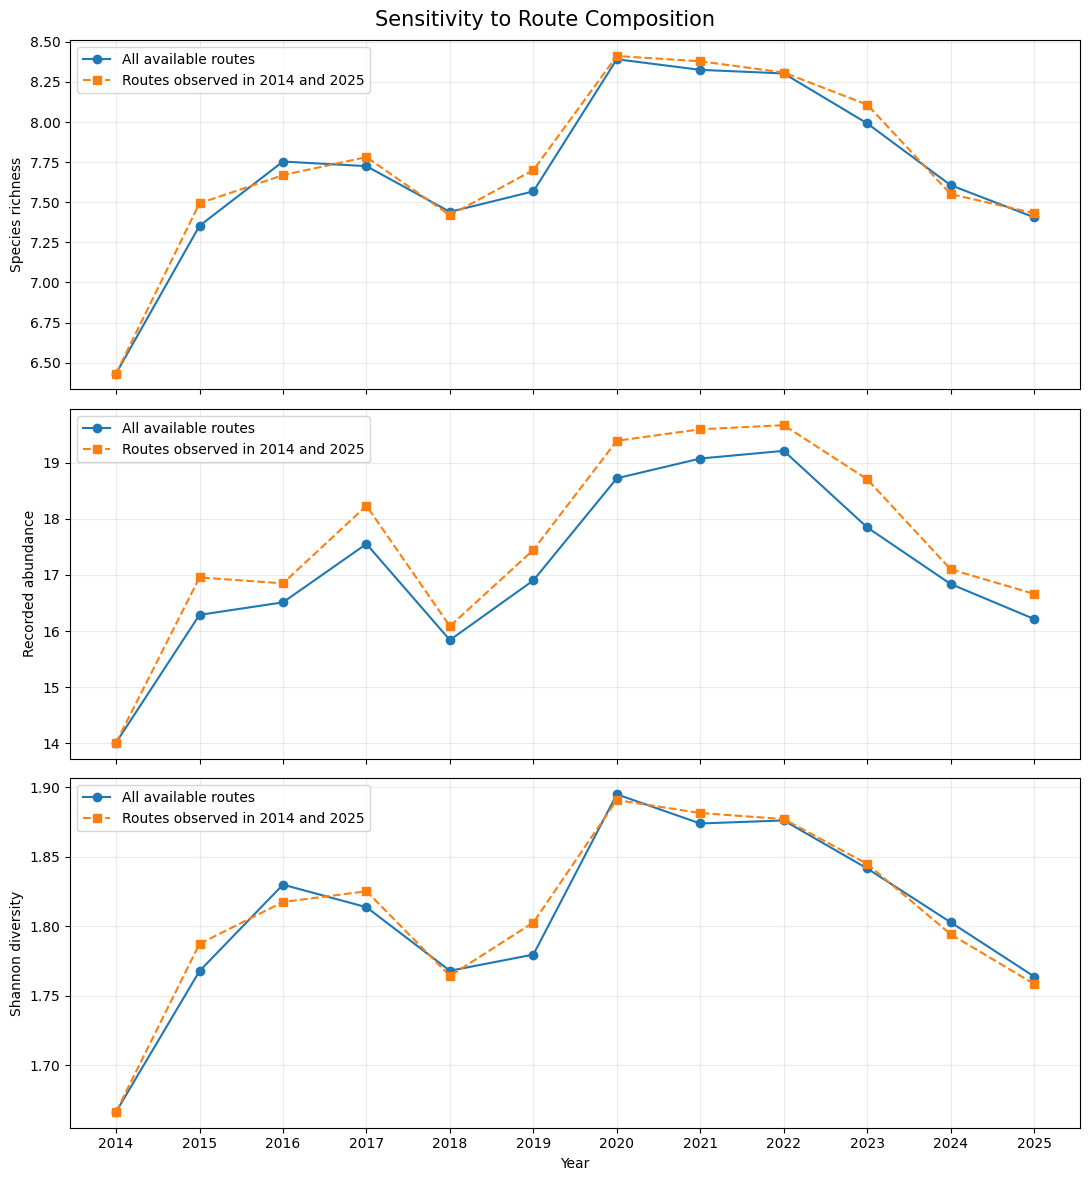

In [13]:
routes_2014 = set(route_year.loc[
    route_year["year"] == 2014, "route_key"
])

routes_2025 = set(route_year.loc[
    route_year["year"] == 2025, "route_key"
])

common_routes = routes_2014.intersection(routes_2025)

common_route_data = route_year[
    route_year["route_key"].isin(common_routes)
]

annual_all = route_year.groupby("year")[indicators].mean()
annual_common = common_route_data.groupby("year")[indicators].mean()

print(f"Routes in both endpoint years: {len(common_routes)}")

fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

for ax, indicator in zip(axes, indicators):
    ax.plot(
        annual_all.index,
        annual_all[indicator],
        "o-",
        label="All available routes"
    )

    ax.plot(
        annual_common.index,
        annual_common[indicator],
        "s--",
        label="Routes observed in 2014 and 2025"
    )

    ax.set_ylabel(labels[indicator])
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(range(2014, 2026))

fig.suptitle("Sensitivity to Route Composition", fontsize=15)
plt.tight_layout()
plt.show()

## 4. Species-Level Evolution

We investigate the recorded detection frequencies of three
frequently observed species.

For each species, a point survey is assigned a value of 1 if
the species was detected, and 0 otherwise.

We calculate detection frequencies within each route-year,
then average across routes with equal weight.

Annual 95% confidence intervals use the route-level variation.
These estimates describe recorded detection, not true occupancy
or population abundance.

In [14]:
points = pd.read_csv(
    ROOT / "data/processed/point_surveys.csv"
)

observations = pd.read_csv(
    ROOT / "data/processed/observations_clean.csv"
)

survey_key = ["route_key", "date", "visit", "point"]

# Exclude surveys with inconsistent counts
valid_surveys = points.loc[
    ~points["count_problem"].fillna(True),
    survey_key + ["year"]
].copy()

# Fixed species selection used throughout the analysis.
selected_species = [
    "sucrier à ventre jaune",
    "viréo à moustaches",
    "sporophile cici"
]

print(
    observations.loc[
        observations["species_key"].str.contains(
            "sucrier|viréo|sporophile",
            case=False,
            na=False
        ),
        "species_key"
    ].value_counts().head(20)
)

species_key
sucrier à ventre jaune    10872
sporophile rougegorge      9161
sporophile cici            6342
viréo à moustaches         5837
sporophile curio            523
Name: count, dtype: int64


/var/folders/x9/c_n70bxn2jlbtkx0w3wy7hd80000gn/T/ipykernel_36827/210482787.py:5: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  observations = pd.read_csv(


In [15]:
def species_detection_frequencies(observations, valid_surveys, species, survey_key):
    """Route-year detection frequencies, including valid surveys with no detection."""
    detected = (
        observations.loc[
            observations["species_key"].eq(species) & observations["selected_count"].gt(0),
            survey_key,
        ]
        .drop_duplicates()
        .assign(detected=1)
    )
    surveys = valid_surveys.merge(detected, on=survey_key, how="left")
    surveys["detected"] = surveys["detected"].fillna(0)
    return (
        surveys.groupby(["route_key", "year"])["detected"]
        .mean()
        .reset_index()
    )


species_route_frequencies = {
    species: species_detection_frequencies(observations, valid_surveys, species, survey_key)
    for species in selected_species
}
species_results = {
    species: annual_confidence_intervals(frequencies, "detected")
    for species, frequencies in species_route_frequencies.items()
}

for species, table in species_results.items():
    print(f"\n{species.upper()}")
    display(table.round(4))


SUCRIER À VENTRE JAUNE


,year,mean,n,se,ci_lower,ci_upper
0,2014,0.4001,40.0,0.0654,0.2679,0.5324
1,2015,0.4140,53.0,0.0564,0.3007,0.5272
2,2016,0.4182,59.0,0.0538,0.3106,0.5259
3,2017,0.4175,60.0,0.0539,0.3097,0.5253
4,2018,0.4041,64.0,0.0502,0.3038,0.5044
5,2019,0.4132,64.0,0.0514,0.3105,0.5158
6,2020,0.4361,63.0,0.0542,0.3278,0.5443
7,2021,0.3598,63.0,0.0527,0.2545,0.4652
8,2022,0.4180,63.0,0.0532,0.3117,0.5244
9,2023,0.4154,64.0,0.0523,0.3109,0.5199



VIRÉO À MOUSTACHES


,year,mean,n,se,ci_lower,ci_upper
0,2014,0.1457,40.0,0.0348,0.0752,0.2162
1,2015,0.2269,53.0,0.0392,0.1483,0.3056
2,2016,0.2341,59.0,0.0387,0.1566,0.3116
3,2017,0.2275,60.0,0.0359,0.1557,0.2993
4,2018,0.2119,64.0,0.0331,0.1457,0.2781
5,2019,0.2452,64.0,0.0373,0.1706,0.3198
6,2020,0.2739,63.0,0.0408,0.1925,0.3554
7,2021,0.1926,63.0,0.0371,0.1184,0.2668
8,2022,0.2688,63.0,0.0400,0.1888,0.3487
9,2023,0.2700,64.0,0.0405,0.1890,0.3510



SPOROPHILE CICI


,year,mean,n,se,ci_lower,ci_upper
0,2014,0.2310,40.0,0.0473,0.1352,0.3267
1,2015,0.2268,53.0,0.0400,0.1465,0.3071
2,2016,0.2471,59.0,0.0411,0.1648,0.3293
3,2017,0.2317,60.0,0.0401,0.1515,0.3118
4,2018,0.2337,64.0,0.0369,0.1599,0.3076
5,2019,0.2183,64.0,0.0353,0.1477,0.2889
6,2020,0.2235,63.0,0.0363,0.1510,0.2960
7,2021,0.1976,63.0,0.0373,0.1231,0.2721
8,2022,0.2359,63.0,0.0397,0.1566,0.3152
9,2023,0.2295,64.0,0.0358,0.1580,0.3011


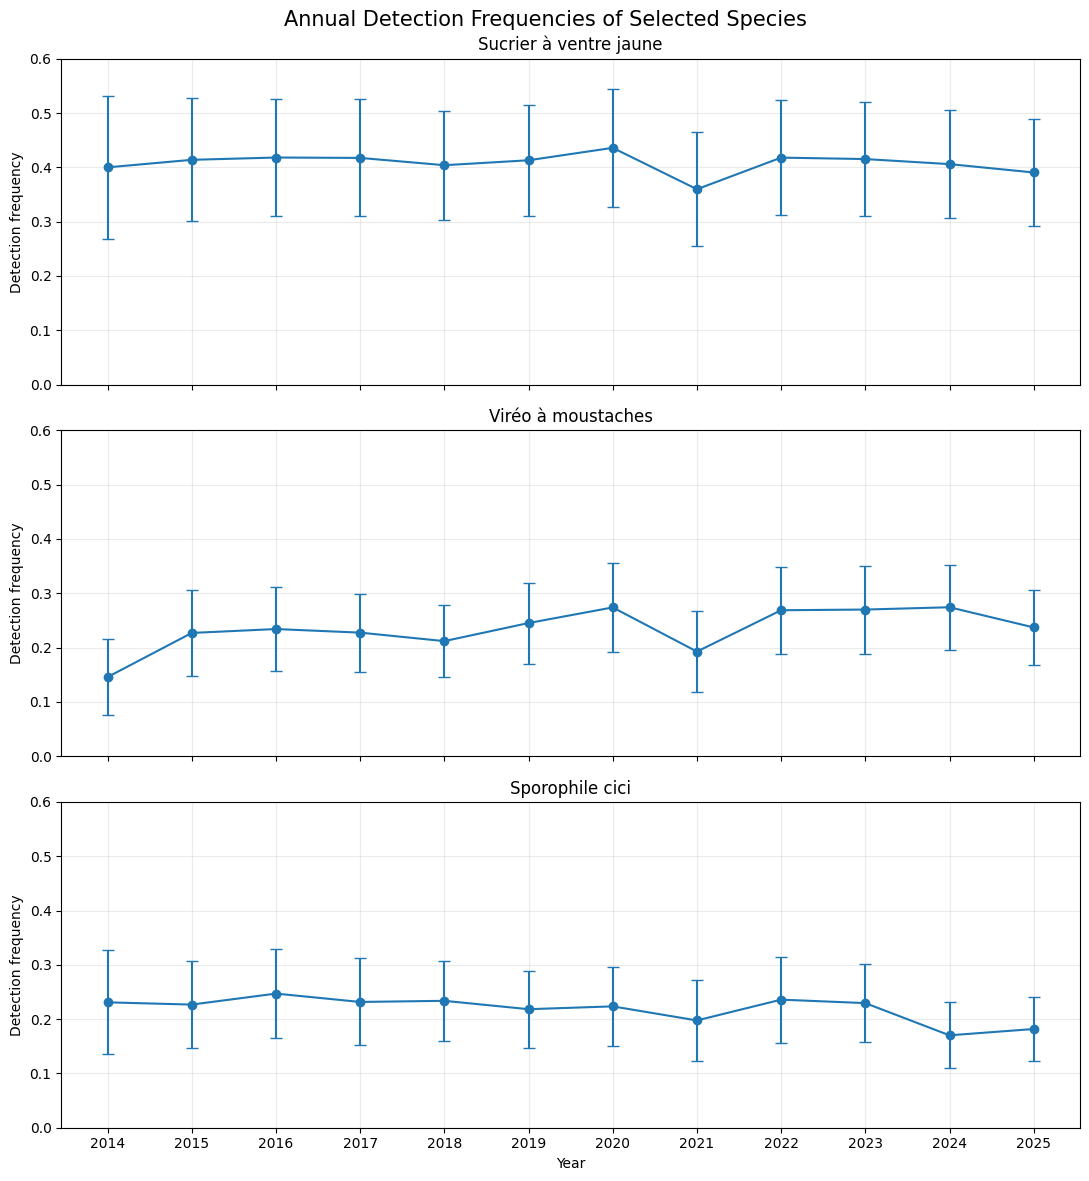

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

for ax, species in zip(axes, selected_species):
    table = species_results[species]

    ax.errorbar(
        table["year"],
        table["mean"],
        yerr=[
            table["mean"] - table["ci_lower"],
            table["ci_upper"] - table["mean"]
        ],
        fmt="o-",
        capsize=4
    )

    ax.set_ylabel("Detection frequency")
    ax.set_title(species.capitalize())
    ax.set_ylim(0, 0.6)
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(range(2014, 2026))

fig.suptitle(
    "Annual Detection Frequencies of Selected Species",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [17]:
species_trends = []
for species, table in species_results.items():
    result = stats.linregress(table["year"] - 2014, table["mean"])
    species_trends.append({
        "species": species,
        "slope": result.slope,
        "r_squared": result.rvalue**2,
        "p_value": result.pvalue,
    })

species_trends = pd.DataFrame(species_trends)
display(species_trends.round(4))

,species,slope,r_squared,p_value
0,sucrier à ventre jaune,-0.0011,0.0409,0.5285
1,viréo à moustaches,0.0065,0.3792,0.0330
2,sporophile cici,-0.0044,0.4580,0.0156


### Interpretation of Species-Level Trends

Sucrier à ventre jaune shows no clear linear trend (slope = −0.0011,
p = 0.5285). Viréo à moustaches increases by approximately 0.65 percentage
points per year (slope = 0.0065, p = 0.0330), while Sporophile cici decreases
by 0.44 percentage points per year (slope = −0.0044, p = 0.0156).

The latter two trends meet the unadjusted 5% threshold. Only Sporophile
cici remains significant under a Bonferroni correction for three comparisons.
These exploratory regressions assume independent annual errors and do not
account explicitly for repeated routes or imperfect detection. The trends
describe recorded detection frequencies, rather than population abundance.

### 4.1 Paired-Route Comparison: 2014 vs. 2025

To investigate whether species-level changes persist when
monitoring locations are held constant, we compare detection
frequencies within routes surveyed in both 2014 and 2025.

For each species, we calculate the difference between its
2025 and 2014 detection frequencies at each eligible route.

We then estimate the mean paired difference, construct a
95% Student's t-confidence interval, and test whether
the mean change differs from zero.

This comparison reduces sensitivity to changes in route
composition, but does not control for changes in detection
conditions or survey effort within routes.

In [18]:
paired_species_data = {}
for species, frequencies in species_route_frequencies.items():
    paired = (
        frequencies.loc[frequencies["year"].isin([2014, 2025])]
        .pivot(index="route_key", columns="year", values="detected")
        .dropna(subset=[2014, 2025])
    )
    paired["difference"] = paired[2025] - paired[2014]
    paired_species_data[species] = paired
    print(f"{species}: {len(paired)} paired routes")

sucrier à ventre jaune: 40 paired routes
viréo à moustaches: 40 paired routes
sporophile cici: 40 paired routes


In [19]:
def summarize_paired_change(paired, start_year=2014, end_year=2025):
    """Summarize complete endpoint pairs with a t interval and paired t-test."""
    change = mean_confidence_interval(paired[end_year] - paired[start_year])
    test = stats.ttest_rel(paired[end_year], paired[start_year])
    return {
        "routes": len(paired),
        f"mean_{start_year}": paired[start_year].mean(),
        f"mean_{end_year}": paired[end_year].mean(),
        "change": change["mean"],
        "ci_lower": change["ci_lower"],
        "ci_upper": change["ci_upper"],
        "p_value": test.pvalue,
    }


paired_results = pd.DataFrame([
    {"species": species, **summarize_paired_change(paired)}
    for species, paired in paired_species_data.items()
])
display(paired_results.round(4))

,species,routes,mean_2014,mean_2025,change,ci_lower,ci_upper,p_value
0,sucrier à ventre jaune,40,0.4001,0.4136,0.0135,-0.0525,0.0795,0.6810
1,viréo à moustaches,40,0.1457,0.2477,0.1020,0.0460,0.1581,0.0007
2,sporophile cici,40,0.2310,0.2209,-0.0101,-0.0625,0.0423,0.6994


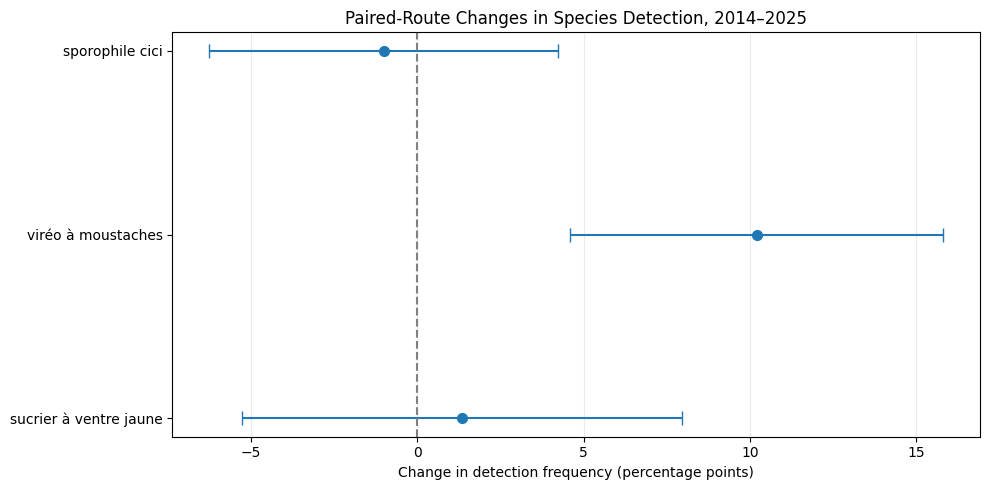

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))

y_pos = np.arange(len(selected_species))

changes = paired_results["change"]

lower_error = changes - paired_results["ci_lower"]
upper_error = paired_results["ci_upper"] - changes

ax.errorbar(
    changes * 100,
    y_pos,
    xerr=[lower_error * 100, upper_error * 100],
    fmt="o",
    capsize=5,
    markersize=7
)

ax.axvline(0, color="gray", linestyle="--")

ax.set_yticks(y_pos)
ax.set_yticklabels(selected_species)
ax.set_xlabel("Change in detection frequency (percentage points)")
ax.set_title("Paired-Route Changes in Species Detection, 2014–2025")

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

### Interpretation of Paired-Route Changes

Each species has 40 paired routes. Viréo à moustaches increases by 10.20
percentage points (95% CI: 4.60–15.81; p = 0.0007). Neither Sucrier à ventre
jaune (p = 0.6810) nor Sporophile cici (p = 0.6994) shows a significant
endpoint difference.

The annual regression and paired comparison answer different questions:
the former describes the full temporal trajectory, while the latter compares
two years at fixed routes. The paired results do not support a corresponding
endpoint decline in Sporophile cici at these routes.

In [21]:
species_abundance = {}

for species in selected_species:

    # Sum recorded counts within each survey
    counts = (
        observations.loc[
            observations["species_key"] == species
        ]
        .groupby(survey_key)["selected_count"]
        .sum(min_count=1)
        .reset_index()
    )

    # Include valid surveys without the species
    species_surveys = valid_surveys.merge(
        counts,
        on=survey_key,
        how="left"
    )

    species_surveys["selected_count"] = (
        species_surveys["selected_count"].fillna(0)
    )

    route_abundance = (
        species_surveys
        .groupby(["route_key", "year"])["selected_count"]
        .mean()
        .reset_index()
    )

    species_abundance[species] = annual_confidence_intervals(
        route_abundance, "selected_count"
    )

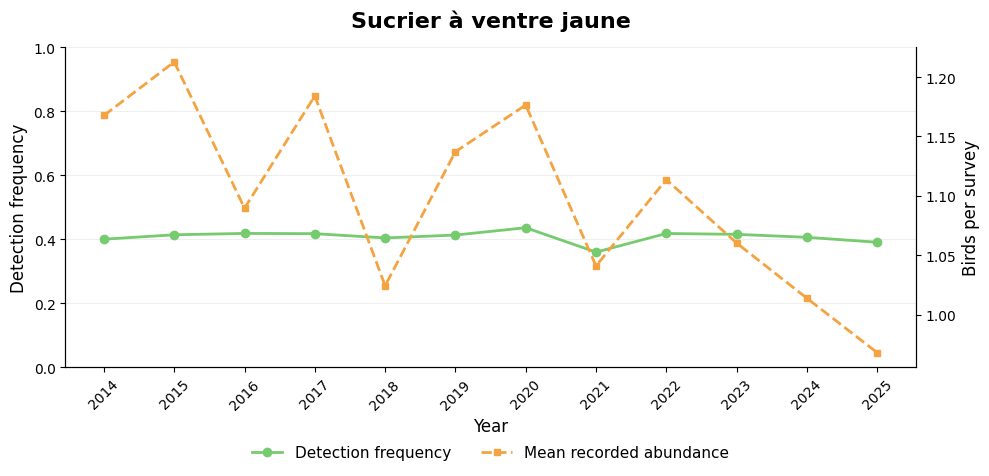

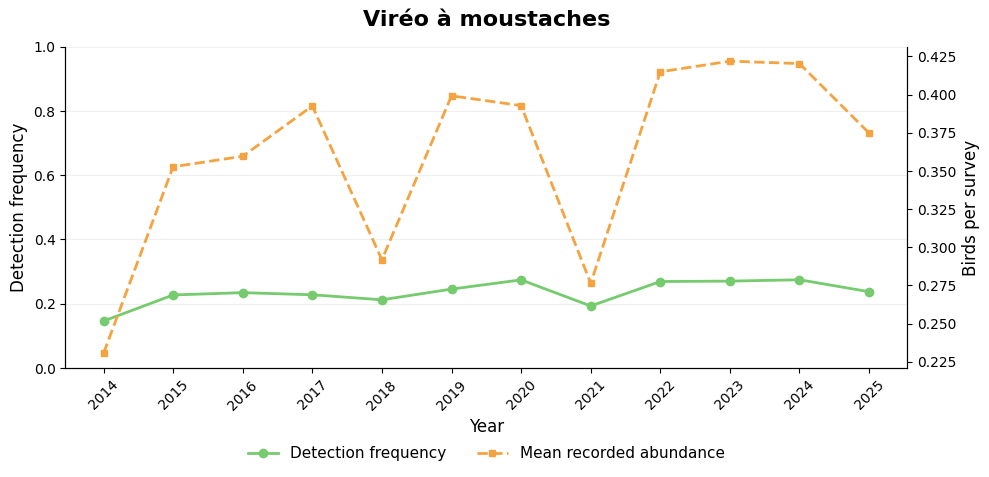

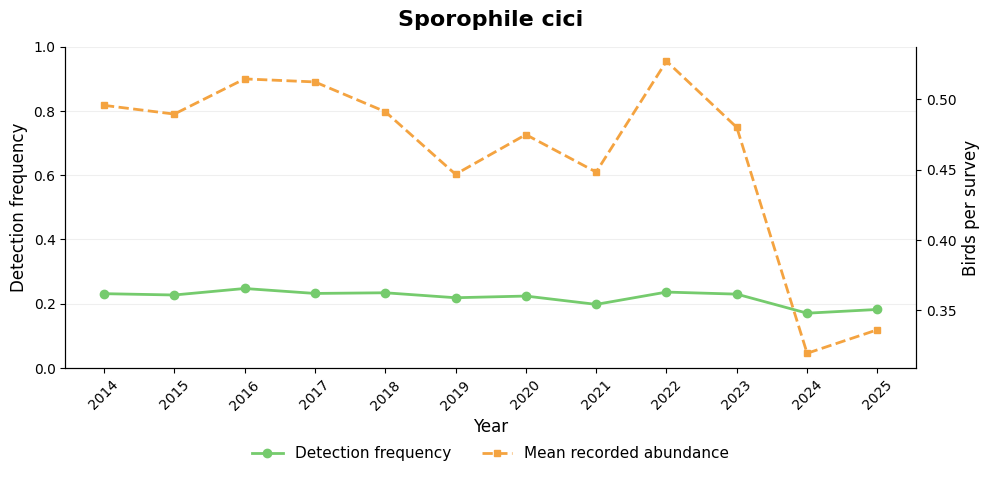

In [22]:
for i, species in enumerate(selected_species):

    detection = species_results[species].sort_values("year")
    abundance = species_abundance[species].sort_values("year")

    fig, ax = plt.subplots(figsize=(10, 5))

    # Left axis: detection frequency
    line1, = ax.plot(
        detection["year"],
        detection["mean"],
        "o-",
        color="#75CB6D",
        linewidth=2,
        markersize=6,
        label="Detection frequency"
    )

    ax.set_ylabel("Detection frequency", fontsize=12)
    ax.set_ylim(0, 1)

    # Right axis: recorded abundance
    ax2 = ax.twinx()

    line2, = ax2.plot(
        abundance["year"],
        abundance["mean"],
        "s--",
        color="#F4A340",
        linewidth=2,
        markersize=5,
        label="Mean recorded abundance"
    )

    ax2.set_ylabel("Birds per survey", fontsize=12)

    ax.set_title(
        species.capitalize(),
        fontsize=16,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Year", fontsize=12)
    ax.set_xticks(range(2014, 2026))
    ax.tick_params(axis="x", rotation=45)

    ax.legend(
        handles=[line1, line2],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=2,
        frameon=False,
        fontsize=11
    )

    ax.grid(axis="y", alpha=0.2)

    ax.spines["top"].set_visible(False)
    ax2.spines["top"].set_visible(False)

    fig.tight_layout()

    fig.savefig(
        f"species_comparison_{i+1}.png",
        dpi=300,
        bbox_inches="tight",
        transparent=True
    )

    plt.show()